# Turno — Experimental Impact | Sprint 1

**Analysis scope:** Registered-host Control vs Test contrasts, not a verified full-population *intention-to-treat* analysis. Six primary candidate indicators (M1–M6), host-resampled 95% uncertainty, cumulative observed payment capture, and S1–S4 sensitivities. **No Ship/Kill/Modified Ship recommendation.**

**Source:** Immutable CSVs (`data/raw/`) and approved EDA 0 checkpoints A/B/C/E/D. All timestamps are UTC. Completion-based baseline: `[2025-07-18, 2025-08-18)`; experiment: `[2025-08-18, 2025-11-20)`; documented payment observation through 2025-12-19 (exact cutoff time not known). Checkout: `analysis/eda0-data-foundation` at approved Commit D `13c67f1`.

**Interpretation boundary:** `captured_at` is observed timestamp evidence, **not settlement confirmation**. `payment_logs.created_at` is never substituted for an event timestamp. Host exposure registration does not prove original randomization or technical treatment delivery; post-exposure subsets are descriptive sensitivities only. M6 is conditional on completed projects, potentially post-treatment selected.

**Inference:** 2,000 percentile bootstrap replicates stratified by registered Control/Test group, resampling hosts; cluster all projects from a host. M6 resamples host numerators and denominators jointly. Seed `20261029`. Intervals are descriptive 95% CIs without multiple-comparison adjustment; a CI including zero does not imply equivalence/noninferiority.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

ROOT=Path.cwd().resolve()
while not (ROOT/'src'/'experiment_impact.py').exists() and ROOT!=ROOT.parent:
    ROOT=ROOT.parent
if not (ROOT/'src'/'experiment_impact.py').exists():
    raise FileNotFoundError('Run from within the project and keep src/experiment_impact.py in place.')
sys.path.insert(0,str(ROOT))
from src.experiment_impact import (
    BASELINE_START, EXPERIMENT_START, EXPERIMENT_END, CS_START, CS_END,
    build_project_panel, build_host_panel, point_estimates, bootstrap_host_differences,
    baseline_hc3, capture_horizon_table, bootstrap_capture_horizons,
    parse_utc, SEED, METRICS,
)

hosts=pd.read_csv(ROOT/'data/raw/experiment_exposures.csv',dtype='string')
assignments=pd.read_csv(ROOT/'data/raw/assignments.csv',dtype='string')
logs=pd.read_csv(ROOT/'data/raw/payment_logs.csv',dtype='string')
project=build_project_panel(hosts,assignments,logs)
experiment=project.loc[project.in_experiment].copy()
panel=build_host_panel(hosts,project)
assert len(panel)==len(hosts)==14708
assert len(project)==len(assignments)==279847 and len(logs)==306957
assert len(experiment)==panel.completed.sum()
assert experiment['coverage_D14'].eq('within_documented_horizon_conservative').all()
assert experiment['capture_D14'].sum()==panel.captured_D14.sum()
assert panel['completed'].eq(panel['captured_D14']+panel['not_captured_D14']).all()
print('Registered hosts by group:',panel.experiment_group.value_counts().to_dict())
print('Completed projects, experiment:',len(experiment))
print('Host zeros:',int(panel.completed.eq(0).sum()),'D14 conservative coverage:',len(experiment),'out of',len(experiment))
print('D30 last-day uncertain:',int(experiment.coverage_D30.eq('last_day_time_uncertain').sum()))
print('Before recorded exposure (completed):',int(experiment.completed_pre_exposure.sum()))
print('Booked before exposure, completed after exposure:',int((~experiment.completed_pre_exposure & experiment.created_pre_exposure).sum()))

Registered hosts by group: {'control': 7377, 'test': 7331}
Completed projects, experiment: 201302
Host zeros: 836 D14 conservative coverage: 201302 out of 201302
D30 last-day uncertain: 1252
Before recorded exposure (completed): 5091
Booked before exposure, completed after exposure: 65294


## A. Executive results — M1–M6

**Denominators:** M1–M5 have *all registered hosts in each group* (7,377 Control; 7,331 Test). M6 is a *ratio of project totals* (98,855 and 102,447 completed projects) with host-cluster uncertainty. M1/M4/M5 are project counts per host; M2 is a count of source-flagged first-ever completions per host; M3 and M6 are proportions. M5 means **no capture timestamp observed by D14**, not payment failure or money lost.

**D14:** Every experimental project's `completed_at + 14 elapsed days` is before `2025-12-19T00:00:00Z`, the conservative last-day boundary under the documented follow-up premise. This establishes theoretical window eligibility, not independently verified completeness of each financial event log. Pre-completion captures count toward all eligible windows.

In [2]:
effects=bootstrap_host_differences(panel,n_boot=2000,seed=SEED)
assert (effects.valid_bootstrap_replicates==2000).all()
assert np.isclose(effects.set_index('metric').loc['M1_completed_per_host','difference'],
                  effects.set_index('metric').loc['M4_captured_D14_per_host','difference']+
                  effects.set_index('metric').loc['M5_not_captured_D14_per_host','difference'])
display(effects.round(6))
reconciliation=experiment.groupby('experiment_group').agg(
    projects=('assignment_id','size'),captured_by_D14=('capture_D14','sum'),
    first_ever=('is_first_true','sum'),pre_completion_capture=('captured_before_completion','sum')
)
reconciliation['not_observed_by_D14']=reconciliation.projects-reconciliation.captured_by_D14
assert (reconciliation.captured_by_D14+reconciliation.not_observed_by_D14==reconciliation.projects).all()
assert int(reconciliation.projects.sum())==len(experiment)
display(reconciliation)

,metric,control,test,difference,relative_percent,ci95_low,ci95_high,bootstrap_replicates,valid_bootstrap_replicates
0,M1_completed_per_host,13.400434,13.974492,0.574058,4.283877,-0.332201,1.598279,2000,2000
1,M2_first_ever_per_host,0.136099,0.150866,0.014767,10.850582,0.003345,0.025504,2000,2000
2,M3_hosts_2plus,0.807510,0.817215,0.009705,1.201811,-0.003082,0.022746,2000,2000
3,M4_captured_D14_per_host,13.327504,13.884872,0.557368,4.182089,-0.342614,1.562049,2000,2000
4,M5_not_captured_D14_per_host,0.072929,0.089619,0.016690,22.885222,-0.012669,0.042872,2000,2000
5,M6_capture_D14_project_rate,0.994558,0.993587,-0.000971,-0.097607,-0.002877,0.001169,2000,2000


,projects,captured_by_D14,first_ever,pre_completion_capture,not_observed_by_D14
experiment_group,,,,,
control,98855,98317,1004,63,538
test,102447,101790,1106,38,657


### Interpretation of the executive comparison

Interpret the confidence intervals **at the host cluster level**, not by treating every completed project as independent. The primary experiment-wide comparisons preserve 836 registered hosts with zero completions, all 5,091 experimental completions before recorded exposure, and all 65,294 projects booked before exposure but completed afterward. No alternative filters replace these main population estimates.

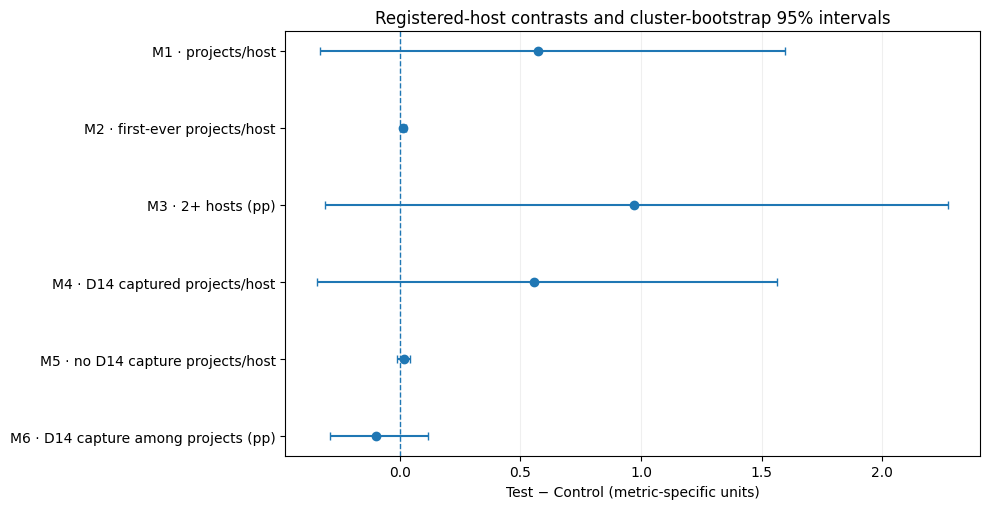

Mixed measurement units: compare interval positions against 0, not bar lengths between metrics.


In [3]:
# One uncluttered effect-size chart. Proportions use percentage points; counts use projects/host.
chart=effects.copy()
chart['display_diff']=np.where(chart.metric.isin(['M3_hosts_2plus','M6_capture_D14_project_rate']),chart.difference*100,chart.difference)
chart['display_low']=np.where(chart.metric.isin(['M3_hosts_2plus','M6_capture_D14_project_rate']),chart.ci95_low*100,chart.ci95_low)
chart['display_high']=np.where(chart.metric.isin(['M3_hosts_2plus','M6_capture_D14_project_rate']),chart.ci95_high*100,chart.ci95_high)
fig,ax=plt.subplots(figsize=(10,5.2))
labels=['M1 · projects/host','M2 · first-ever projects/host','M3 · 2+ hosts (pp)','M4 · D14 captured projects/host','M5 · no D14 capture projects/host','M6 · D14 capture among projects (pp)']
y=np.arange(len(chart));x=chart.display_diff.to_numpy()
ax.errorbar(x,y,xerr=np.vstack([x-chart.display_low.to_numpy(),chart.display_high.to_numpy()-x]),fmt='o',capsize=3)
ax.axvline(0,linestyle='--',linewidth=1)
ax.set_yticks(y,labels);ax.invert_yaxis();ax.set_xlabel('Test − Control (metric-specific units)')
ax.set_title('Registered-host contrasts and cluster-bootstrap 95% intervals')
ax.grid(axis='x',alpha=.2)
fig.tight_layout();display(fig);plt.close(fig)
print('Mixed measurement units: compare interval positions against 0, not bar lengths between metrics.')

## B. Payment reliability and capture speed

Eligibility uses *elapsed time* from project completion, not calendar-day subtraction. At D30, projects with a deadline on 2025-12-19 are excluded because that day's final observation hour is unverified. D1/D7/D14 use the full experiment project set. Rate differences have separate 2,000-replicate, host-clustered joint-numerator/denominator bootstrap intervals.

In [4]:
horizon=capture_horizon_table(project)
horizon_boot=bootstrap_capture_horizons(hosts,project,n_boot=2000,seed=SEED)
assert horizon.loc[horizon.horizon.eq('D14'),'uncertain_or_beyond'].sum()==0
assert horizon.loc[horizon.horizon.eq('D30'),'uncertain_or_beyond'].sum()==1252
assert (horizon.captured+horizon.not_observed==horizon.eligible_projects).all()
display(horizon)
display(horizon_boot.round(6))
print('Capture before project completion (experiment, first recorded capture):',int(experiment.captured_before_completion.sum()))
print('Projects with a timestamp eventually observed, but not by D14:',int((experiment.has_capture & ~experiment.capture_D14).sum()))

,horizon,group,eligible_projects,uncertain_or_beyond,captured,not_observed,rate,captured_pre_completion
0,D1,control,98855,0,97702,1153,0.988336,63
1,D1,test,102447,0,100504,1943,0.981034,38
2,D7,control,98855,0,98245,610,0.993829,63
3,D7,test,102447,0,101648,799,0.992201,38
4,D14,control,98855,0,98317,538,0.994558,63
5,D14,test,102447,0,101790,657,0.993587,38
6,D30,control,98239,616,97751,488,0.995033,63
7,D30,test,101811,636,101227,584,0.994264,37


,horizon,control,test,difference,ci95_low,ci95_high,valid_bootstrap_replicates
0,D1,0.988336,0.981034,-0.007302,-0.011220,-0.003322,2000
1,D7,0.993829,0.992201,-0.001629,-0.003813,0.000910,2000
2,D14,0.994558,0.993587,-0.000971,-0.002877,0.001169,2000
3,D30,0.995033,0.994264,-0.000769,-0.002381,0.000867,2000


Capture before project completion (experiment, first recorded capture): 101
Projects with a timestamp eventually observed, but not by D14: 196


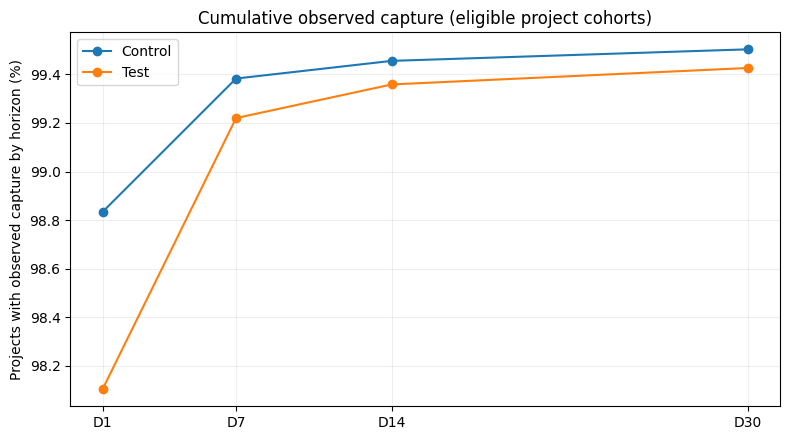

D30 denominator excludes uncertain final-day windows, so it is not the same cohort as D1–D14.


In [5]:
fig,ax=plt.subplots(figsize=(8,4.5))
xs=[1,7,14,30]
for grp in ('control','test'):
    series=horizon.loc[horizon.group.eq(grp)].set_index('horizon').loc[['D1','D7','D14','D30']]
    ax.plot(xs,series.rate.to_numpy()*100,marker='o',label=grp.title())
ax.set_xticks(xs,['D1','D7','D14','D30']);ax.set_ylabel('Projects with observed capture by horizon (%)')
ax.set_title('Cumulative observed capture (eligible project cohorts)')
ax.legend();ax.grid(alpha=.2);fig.tight_layout();display(fig);plt.close(fig)
print('D30 denominator excludes uncertain final-day windows, so it is not the same cohort as D1–D14.')

## C. Host behavior

The source flag denotes a host's reported historical first *completion* (not necessarily its first arrival at Turno). An observed second completion after such a flag is a descriptive within-extract behavior. It is **not** a treatment effect on conversion conditional on first completion.

In [6]:
first=experiment.loc[experiment.is_first_true,['assignment_id','host_id','completed_utc','experiment_group']].copy()
future=experiment[['host_id','completed_utc']].groupby('host_id')['completed_utc'].max()
first['observed_later_completion']=first.host_id.map(future).gt(first.completed_utc)
first_summary=first.groupby('experiment_group').agg(first_flagged_projects=('assignment_id','size'),
            first_flagged_hosts=('host_id','nunique'),hosts_with_later_observed_completion=('observed_later_completion','sum'))
first_summary['conditional_share_descriptive_only']=first_summary.hosts_with_later_observed_completion/first_summary.first_flagged_hosts
assert first.assignment_id.is_unique and first.host_id.is_unique
assert int(first_summary.first_flagged_projects.sum())==int(experiment.is_first_true.sum())
display(first_summary.round(5))
print('Host-level M2 and M3 95% intervals are reported in the executive table; no causal transition/conversion claim.')

,first_flagged_projects,first_flagged_hosts,hosts_with_later_observed_completion,conditional_share_descriptive_only
experiment_group,,,,
control,1004,1004,684,0.68127
test,1106,1106,742,0.67089


Host-level M2 and M3 95% intervals are reported in the executive table; no causal transition/conversion claim.


## D. Robustness — S1: capture evidence definition

Project classifications across the entire experiment are distinct from *timely D14 capture*. `has_success` contains **no capture timestamp**; `has_concordant` confirms both pieces on the same attempt, but an attempt can be concordant outside D14. Therefore **neither status nor concordance is labeled as a D14 metric**. Difference in membership is reported separately from group differences in descriptive totals.

In [7]:
s1=[]
for g,z in experiment.groupby('experiment_group'):
    n=len(z);nh=int((panel.experiment_group==g).sum())
    for name,col in [('any_timestamp','has_capture'),('any_succeeded','has_success'),('same_attempt_concordant','has_concordant')]:
        captured=int(z[col].sum());s1.append({'group':g,'candidate':name,'projects_with_evidence':captured,
                        'completed_projects':n,'registered_hosts':nh,'share_of_completed_projects':captured/n,
                        'projects_per_registered_host':captured/nh})
s1=pd.DataFrame(s1)
pivot=s1.pivot(index='candidate',columns='group',values='share_of_completed_projects')
pivot['test_minus_control']=pivot.test-pivot.control
display(s1.round(6));display(pivot.round(6))
changes=experiment.groupby('experiment_group').apply(lambda z:pd.Series({
    'status_vs_timestamp_membership_changes':int((z.has_success^z.has_capture).sum()),
    'timestamp_vs_concordant_membership_changes':int((z.has_capture^z.has_concordant).sum()),
    'any_timestamp_after_D14_only':int((z.has_capture & ~z.capture_D14).sum())
}),include_groups=False)
display(changes)
assert (s1.groupby('candidate').completed_projects.sum()==len(experiment)).all()
assert int(changes.status_vs_timestamp_membership_changes.sum())==int((experiment.has_success^experiment.has_capture).sum())

,group,candidate,projects_with_evidence,completed_projects,registered_hosts,share_of_completed_projects,projects_per_registered_host
0,control,any_timestamp,98405,98855,7377,0.995448,13.339433
1,control,any_succeeded,97948,98855,7377,0.990825,13.277484
2,control,same_attempt_concordant,97880,98855,7377,0.990137,13.268266
3,test,any_timestamp,101898,102447,7331,0.994641,13.899604
4,test,any_succeeded,101372,102447,7331,0.989507,13.827854
5,test,same_attempt_concordant,101319,102447,7331,0.988989,13.820625


group,control,test,test_minus_control
candidate,,,
any_succeeded,0.990825,0.989507,-0.001318
any_timestamp,0.995448,0.994641,-0.000807
same_attempt_concordant,0.990137,0.988989,-0.001148


,status_vs_timestamp_membership_changes,timestamp_vs_concordant_membership_changes,any_timestamp_after_D14_only
experiment_group,,,
control,483,525,88
test,538,579,108


## D. Robustness — S2: recorded exposure chronology

Main outcomes include projects completed before recorded exposure and projects reserved before recorded exposure. Below are *descriptive partitions only*, not alternate intention-to-treat effect estimates. A host's `first_exposed_at` is not proven to be the original allocation instant or the start of technical treatment.

In [8]:
s2=experiment.groupby(['experiment_group','completed_pre_exposure']).agg(
    projects=('assignment_id','size'),captured_D14=('capture_D14','sum'),
    booked_before_recorded_exposure=('created_pre_exposure','sum')).reset_index()
display(s2)
assert int(s2.projects.sum())==len(experiment)
assert int(experiment.completed_pre_exposure.sum())==5091
assert int((~experiment.completed_pre_exposure & experiment.created_pre_exposure).sum())==65294
exposure=hosts[['host_id','experiment_group','first_exposed_at']].copy()
exposure['potential_exposure_days']=(EXPERIMENT_END-parse_utc(exposure.first_exposed_at)).dt.total_seconds()/86400
exposure_summary=exposure.groupby('experiment_group').potential_exposure_days.agg(['count','min','median','mean','max'])
display(exposure_summary.round(3))
post_panel=build_host_panel(hosts,project,restrict_after_exposure=True)
post=point_estimates(post_panel).pivot(index='metric',columns='group',values='estimate')
post['test_minus_control']=post.test-post.control
display(post.loc[['M1_completed_per_host','M4_captured_D14_per_host','M5_not_captured_D14_per_host']].round(5))
print('Post-recorded-exposure restriction is NOT a causally equivalent replacement for the main sample.')

,experiment_group,completed_pre_exposure,projects,captured_D14,booked_before_recorded_exposure
0,control,False,96282,95790,32299
1,control,True,2573,2527,2573
2,test,False,99929,99328,32995
3,test,True,2518,2462,2518


,count,min,median,mean,max
experiment_group,,,,,
control,7377,0.385,87.073,75.584,93.448
test,7331,0.484,86.912,75.334,93.437


group,control,test,test_minus_control
metric,,,
M1_completed_per_host,13.05165,13.63102,0.57937
M4_captured_D14_per_host,12.98495,13.54904,0.56409
M5_not_captured_D14_per_host,0.06669,0.08198,0.01529


Post-recorded-exposure restriction is NOT a causally equivalent replacement for the main sample.


## D. Robustness — S3: operational CS incident

Remove projects **completed** during `[2025-09-17T00:00Z, 2025-10-01T00:00Z)` symmetrically. Keep every registered host as a denominator. This changes the target observation period; it does *not* recover the counterfactual absence of the incident.

In [9]:
incident_experiment=experiment.loc[experiment.incident_completed]
incident_panel=build_host_panel(hosts,project,omit_incident=True)
inc_boot=bootstrap_host_differences(incident_panel,n_boot=2000,seed=SEED)
main_d=effects.set_index('metric').difference
s3=inc_boot[['metric','difference','ci95_low','ci95_high']].copy()
s3.insert(1,'full_experiment_difference',s3.metric.map(main_d))
s3['change_from_full_difference']=s3.difference-s3.full_experiment_difference
assert len(incident_panel)==len(hosts)
assert int(panel.completed.sum()-incident_panel.completed.sum())==len(incident_experiment)
print('Incident-window project exclusions by group:',incident_experiment.experiment_group.value_counts().to_dict())
display(s3.round(6))

Incident-window project exclusions by group: {'test': 15486, 'control': 14974}


,metric,full_experiment_difference,difference,ci95_low,ci95_high,change_from_full_difference
0,M1_completed_per_host,0.574058,0.491481,-0.266700,1.348869,-0.082577
1,M2_first_ever_per_host,0.014767,0.015584,0.004969,0.025529,0.000816
2,M3_hosts_2plus,0.009705,0.007821,-0.005214,0.021005,-0.001884
3,M4_captured_D14_per_host,0.557368,0.477443,-0.279267,1.334499,-0.079925
4,M5_not_captured_D14_per_host,0.016690,0.014038,-0.011900,0.038356,-0.002652
5,M6_capture_D14_project_rate,-0.000971,-0.000953,-0.003011,0.001319,0.000018


## D. Robustness — S4: pre-experiment baseline activity

Secondary linear host-level adjustment: outcome ~ registered Test + number of completed projects during baseline; HC3 heteroskedasticity-robust 95% CI. The baseline covariate is measured before the first recorded exposures. This is **not difference-in-differences**, nor a correction for undocumented randomization or exposure timing. Report heterogeneity by baseline-zero vs baseline-positive only descriptively.

In [10]:
adjusted=baseline_hc3(panel)
base_name={'completed':'M1_completed_per_host','captured_D14':'M4_captured_D14_per_host','not_captured_D14':'M5_not_captured_D14_per_host'}
adjusted.insert(1,'unadjusted_difference',adjusted.outcome.map({k:main_d[v] for k,v in base_name.items()}))
display(adjusted.round(6))
rows=[]
for label,mask in [('baseline_zero',panel.baseline_completions.eq(0)),('baseline_positive',panel.baseline_completions.gt(0))]:
    sub=panel.loc[mask]
    pt=point_estimates(sub).pivot(index='metric',columns='group',values='estimate')
    for met in ('M1_completed_per_host','M4_captured_D14_per_host','M5_not_captured_D14_per_host'):
        rows.append({'baseline_group':label,'metric':met,'control_hosts':int(sub.experiment_group.eq('control').sum()),
                     'test_hosts':int(sub.experiment_group.eq('test').sum()),'difference':pt.loc[met,'test']-pt.loc[met,'control']})
base_heterogeneity=pd.DataFrame(rows)
display(base_heterogeneity.round(6))

,outcome,unadjusted_difference,adjusted_test_minus_control,ci95_low,ci95_high,se_hc3,n_hosts,baseline_coefficient
0,completed,0.574058,0.174202,-0.204823,0.553227,0.193384,14708,2.213153
1,captured_D14,0.557368,0.160374,-0.219774,0.540521,0.193956,14708,2.197314
2,not_captured_D14,0.016690,0.013828,-0.014159,0.041816,0.014280,14708,0.015839


,baseline_group,metric,control_hosts,test_hosts,difference
0,baseline_zero,M1_completed_per_host,2177,2247,-0.064649
1,baseline_zero,M4_captured_D14_per_host,2177,2247,-0.094458
2,baseline_zero,M5_not_captured_D14_per_host,2177,2247,0.029809
3,baseline_positive,M1_completed_per_host,5200,5084,1.069825
4,baseline_positive,M4_captured_D14_per_host,5200,5084,1.058572
5,baseline_positive,M5_not_captured_D14_per_host,5200,5084,0.011254


## E. Validations and decision evidence (not a recommendation)

**Validation gates:** primary host counts; source project/log keys and joins; completed-project half-open UTC windows; conservative D14 documented-horizon eligibility; numerator + complement = denominator per host; M6 project-weighted group ratios and joint host bootstrap; D30 final-day exclusions; S3 incident group symmetry and unchanged registered-host denominator; independent standard-library CSV check (reported separately). Seed and replicate counts shown above.

**Decision boundary:** Activity and observed capture can move together, but failure-to-observe by D14 is not proven financial loss. Different field evidence affects project classification. D1 capture time, D14 proportional capture, and project counts measure different constructs. Relative activity exposure is nonuniform by recorded exposure date, including pre-exposure completions. The dataset does not identify acceptance rates, amount owed/settled, comprehensive CS actions, or an incident-free counterfactual. Final Ship/Kill/Modified Ship decision is reserved for human reviewers.

In [11]:
assert int(panel.completed.sum())==int(experiment.shape[0])
assert int(panel.captured_D14.sum())+int(panel.not_captured_D14.sum())==len(experiment)
assert int(panel.loc[panel.experiment_group.eq('control'),'completed'].sum())==98855
assert int(panel.loc[panel.experiment_group.eq('test'),'completed'].sum())==102447
assert int(experiment.loc[experiment.capture_D14,'captured_before_completion'].sum())==int(experiment.captured_before_completion.sum())
assert len(effects)==6 and (effects.ci95_low<=effects.ci95_high).all()
assert (effects.bootstrap_replicates==2000).all()
assert (horizon_boot.valid_bootstrap_replicates==2000).all()
print('PASS: 6 candidate metric estimates, 95% cluster-bootstrap intervals, project/host D14 identity, D30 censoring, S1/S2/S3/S4, baseline HC3, 2 diagnostic charts.')
print('V7 applies to this notebook only after a full clean-kernel run with saved outputs.')

PASS: 6 candidate metric estimates, 95% cluster-bootstrap intervals, project/host D14 identity, D30 censoring, S1/S2/S3/S4, baseline HC3, 2 diagnostic charts.
V7 applies to this notebook only after a full clean-kernel run with saved outputs.
